In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras import layers, models
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

print("TensorFlow Version:", tf.__version__)

In [ ]:
(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.cifar10.load_data()
)

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)

print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

     8192/170498071 ━━━━━━━━━━━━━━━━━━━━ 54:51 19us/step

KeyboardInterrupt: 

In [ ]:
class_names = [
    'Airplane',
    'Automobile',
    'Bird',
    'Cat',
    'Deer',
    'Dog',
    'Frog',
    'Horse',
    'Ship',
    'Truck'
]

NameError: name 'x_train' is not defined

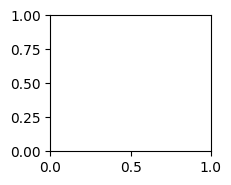

In [ ]:
plt.figure(figsize=(12, 6))

for i in range(15):
    plt.subplot(3, 5, i + 1)

    plt.imshow(x_train[i])

    plt.title(class_names[y_train[i][0]])

    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
x_train = x_train.astype('float32') / 255.0

x_test = x_test.astype('float32') / 255.0

y_train = y_train.flatten()
y_test = y_test.flatten()

print("Training data normalized.")
print("Testing data normalized.")

NameError: name 'x_train' is not defined

In [ ]:
data_augmentation = models.Sequential([

    layers.RandomFlip("horizontal"),

    layers.RandomRotation(0.1),

    layers.RandomZoom(0.1),

    layers.RandomTranslation(0.1, 0.1)

])

In [ ]:
plt.figure(figsize=(12, 5))

for i in range(5):

    original = x_train[i]

    augmented = data_augmentation(
        tf.expand_dims(original, axis=0),
        training=True
    )

    plt.subplot(2, 5, i + 1)
    plt.imshow(original)
    plt.title("Original")
    plt.axis('off')

    plt.subplot(2, 5, i + 6)
    plt.imshow(augmented[0].numpy())
    plt.title("Augmented")
    plt.axis('off')

plt.tight_layout()
plt.show()

NameError: name 'x_train' is not defined

<Figure size 1200x500 with 0 Axes>

In [ ]:
model = models.Sequential([

    # Input
    layers.Input(shape=(32, 32, 3)),

    # Data augmentation
    data_augmentation,

    # First convolution block
    layers.Conv2D(32, (3,3),
                  activation='relu',
                  padding='same'),

    layers.MaxPooling2D((2,2)),

    # Second convolution block
    layers.Conv2D(64, (3,3),
                  activation='relu',
                  padding='same'),

    layers.MaxPooling2D((2,2)),

    # Third convolution block
    layers.Conv2D(128, (3,3),
                  activation='relu',
                  padding='same'),

    # Classification layers
    layers.Flatten(),

    layers.Dense(128, activation='relu'),

    layers.Dropout(0.3),

    layers.Dense(10, activation='softmax')
])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,143,242 (4.36 MB)

 Trainable params: 1,143,242 (4.36 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(

    optimizer='adam',

    loss='sparse_categorical_crossentropy',

    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


In [ ]:
history = model.fit(

    x_train,
    y_train,

    epochs=20,

    batch_size=64,

    validation_split=0.2

)

NameError: name 'x_train' is not defined

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('CNN Model Accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')

plt.legend()
plt.grid()

plt.show()

NameError: name 'history' is not defined

<Figure size 1000x500 with 0 Axes>

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title('CNN Model Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.legend()
plt.grid()

plt.show()

NameError: name 'history' is not defined

<Figure size 1000x500 with 0 Axes>

In [ ]:
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test
)

print("Test Loss:", test_loss)

print("Test Accuracy:",
      test_accuracy * 100, "%")

NameError: name 'x_test' is not defined

In [ ]:
predictions = model.predict(x_test)

y_pred = np.argmax(predictions, axis=1)

NameError: name 'x_test' is not defined

In [ ]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=class_names
    )
)

NameError: name 'y_test' is not defined

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.title("CNN Confusion Matrix")

plt.show()

NameError: name 'y_test' is not defined

In [ ]:
index = 25

image = x_test[index]

prediction = model.predict(
    np.expand_dims(image, axis=0),
    verbose=0
)

predicted_class = np.argmax(prediction)

plt.imshow(image)

plt.title(
    "Predicted: " + class_names[predicted_class]
)

plt.axis('off')

plt.show()

print("Actual Class:",
      class_names[y_test[index]])

print("Predicted Class:",
      class_names[predicted_class])

print("Confidence:",
      np.max(prediction) * 100, "%")

NameError: name 'x_test' is not defined

In [ ]:
model.save("cnn_cifar10_augmented.keras")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

Saving Screenshot 2026-11-03 115619.png to Screenshot 2026-11-03 115619.png


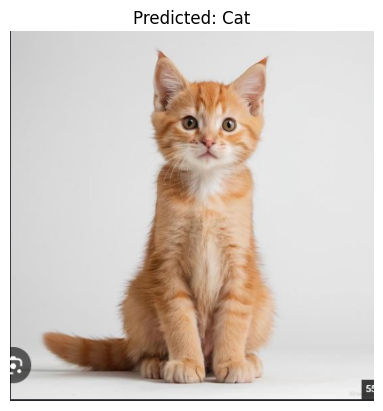

Predicted Class: Cat
Confidence: 10.99 %


In [ ]:
# Upload image
uploaded = files.upload()

# Get uploaded image filename
filename = list(uploaded.keys())[0]

# Open and resize image
img = Image.open(filename).convert('RGB')
img = img.resize((32, 32))

# Convert image to array
img_array = np.array(img) / 255.0

# Add batch dimension
img_array = np.expand_dims(img_array, axis=0)

# Predict
prediction = model.predict(img_array, verbose=0)

predicted_class = np.argmax(prediction)

# Display image
plt.imshow(Image.open(filename))
plt.axis('off')
plt.title("Predicted: " + class_names[predicted_class])
plt.show()

print("Predicted Class:", class_names[predicted_class])
print("Confidence:", round(np.max(prediction) * 100, 2), "%")